In [5]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import subprocess
import numpy as np
from fake_spectra.plot_spectra import PlottingSpectra
spec_file = Path("/projects/pbreysse/lya_forest_CO/lya_storage/Lyman-alpha-ASTRID_z2.5_unzipped/Lyman-alpha-ASTRID_z2.5/spectra_ASTRID_noiseless_z2.5_1000_voxels.hdf5")

sp = PlottingSpectra(
    num=1,
    base="./",
    savedir=str(spec_file.parent),
    savefile=spec_file.name,
    res=None,
)

L = 250000/ 1000.0  # ckpc/h -> cMpc/h
Path("/users/jiawenfan/work/lya_CO/dachshund/dachshund.exe").resolve()
work = Path("astrid_reconstruction").resolve()
nmesh = 64   
# Dachshund output: x, y, z ordering, with z changing fastest
# cube = np.fromfile(
#     work / "map_reconstructed.dat", dtype=np.float64
# ).reshape(nmesh, nmesh, nmesh)

# # Average 5 slices around the center along the z direction
# mid = nmesh // 2
# slice_map = cube[:, :, mid - 4:mid + 5].mean(axis=0)

# # Symmetric color range to show absorption and transmission
# vlim = np.percentile(np.abs(slice_map), 99)

# fig, ax = plt.subplots(figsize=(7, 6))
# im = ax.imshow(
#     slice_map.T,
#     origin="lower",
#     extent=[0, L, 0, L],
#     cmap="RdBu_r",
#     vmin=-vlim,
#     vmax=vlim,
#     interpolation="nearest",
#     aspect="equal",
# )

# ax.set_xlabel(r"$x\;[\mathrm{cMpc}/h]$")
# ax.set_ylabel(r"$y\;[\mathrm{cMpc}/h]$")
# ax.set_title(r"Reconstructed Ly$\alpha$ forest")
# fig.colorbar(im, ax=ax, label=r"$\delta_F = F/\langle F\rangle - 1$")
# plt.tight_layout()
plt.show()

Reading pre-computed spectra (from file /projects/pbreysse/lya_forest_CO/lya_storage/Lyman-alpha-ASTRID_z2.5_unzipped/Lyman-alpha-ASTRID_z2.5/spectra_ASTRID_noiseless_z2.5_1000_voxels.hdf5  )
1000000  sightlines. resolution:  26.69087931631281  z= 2.499999947500001


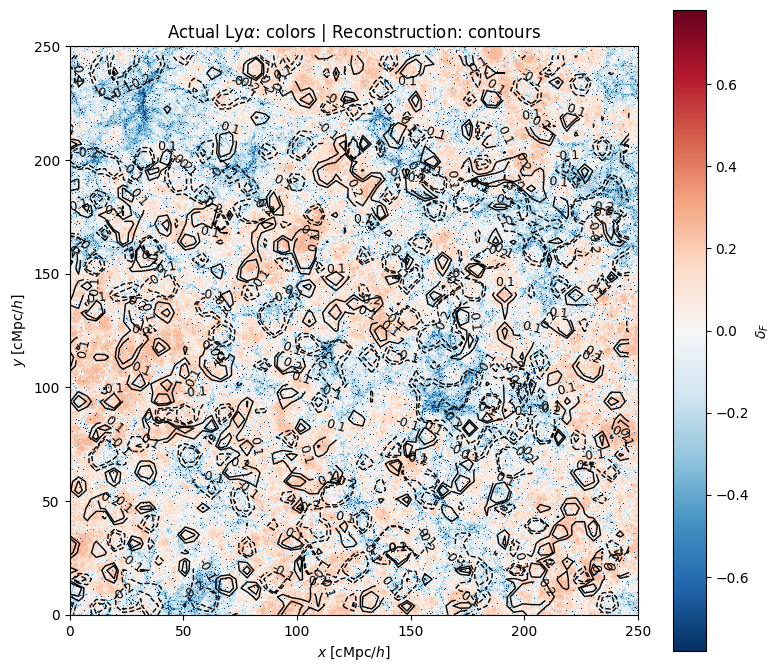

In [6]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

L = 250.0                       # cMpc/h
nmesh = 64                      # Match your Dachshund configuration
z_center = L / 2
depth = 10.0                    # Slab thickness in cMpc/h

# Reconstructed delta_F
recon = np.fromfile(
    work / "map_reconstructed.dat", dtype=np.float64
).reshape(nmesh, nmesh, nmesh)

# Actual delta_F map
true_file = (
    "/projects/pbreysse/lya_forest_CO/lya_storage/"
    "Lyman-alpha-ASTRID_z2.5_unzipped/Lyman-alpha-ASTRID_z2.5/"
    "map_ASTRID_true_0.25_z2.5.hdf5"
)

with h5py.File(true_file, "r") as f:
    data = f["map"]              # Already delta_F; do not normalize again
    z_true = np.arange(data.shape[2]) * L / data.shape[2]
    indices = np.flatnonzero(abs(z_true - z_center) <= depth / 2)
    true_slice = data[:, :, indices[0]:indices[-1] + 1].mean(axis=2)

# Same physical slab in the reconstruction
z_recon = np.arange(nmesh) * L / nmesh
keep = abs(z_recon - z_center) <= depth / 2
recon_slice = recon[:, :, keep].mean(axis=2)

# Coordinates; assumes both arrays are ordered x, y, z
x_true = np.arange(true_slice.shape[0]) * L / true_slice.shape[0]
y_true = np.arange(true_slice.shape[1]) * L / true_slice.shape[1]
x_recon = np.arange(nmesh) * L / nmesh

vlim = np.percentile(abs(true_slice), 99)




fig, ax = plt.subplots(figsize=(8, 7))

im = ax.pcolormesh(
    x_true, y_true, true_slice.T,
    shading="auto", cmap="RdBu_r",
    vmin=-vlim, vmax=vlim,
)

# Negative contours dashed, positive contours solid
levels = np.array([-0.2, -0.1, 0.1, 0.2])
contours = ax.contour(
    x_recon, x_recon, recon_slice.T,
    levels=levels, colors="black", linewidths=1,
)
ax.clabel(contours, inline=True, fontsize=9, fmt="%.1f")

ax.set(
    xlabel=r"$x\;[\mathrm{cMpc}/h]$",
    ylabel=r"$y\;[\mathrm{cMpc}/h]$",
    title=r"Actual Ly$\alpha$: colors | Reconstruction: contours",
    xlim=(0, L), ylim=(0, L),
)
ax.set_aspect("equal")
fig.colorbar(im, ax=ax, label=r"$\delta_F$")
plt.tight_layout()
plt.show()

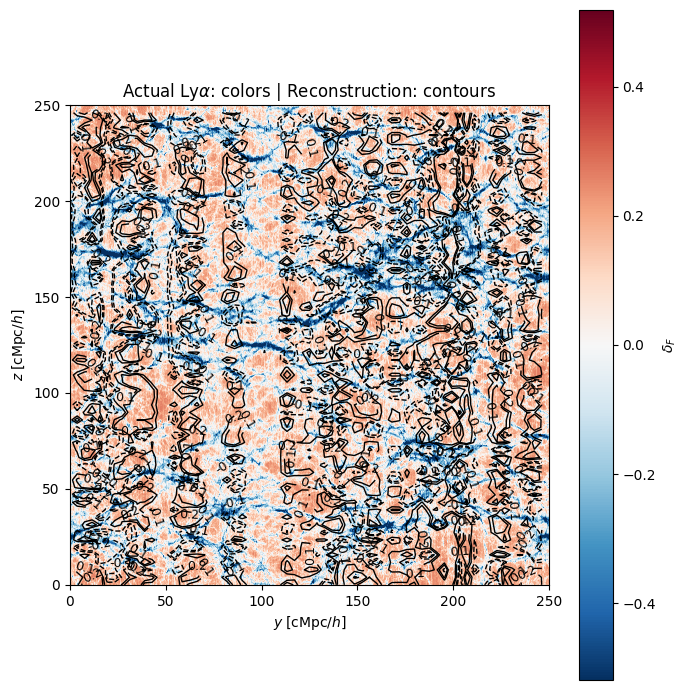

In [7]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

L = 250.0                  # cMpc/h
nmesh = 64                 # Match your Dachshund configuration
x_center = L / 2
depth = 10.0               # Slab thickness in cMpc/h

# Reconstructed delta_F
recon = np.fromfile(
    work / "map_reconstructed.dat", dtype=np.float64
).reshape(nmesh, nmesh, nmesh)

# Actual delta_F map
true_file = (
    "/projects/pbreysse/lya_forest_CO/lya_storage/"
    "Lyman-alpha-ASTRID_z2.5_unzipped/Lyman-alpha-ASTRID_z2.5/"
    "map_ASTRID_true_0.25_z2.5.hdf5"
)

with h5py.File(true_file, "r") as f:
    data = f["map"]  # Already delta_F; do not normalize again

    # Select and average a slab along axis 0
    x_true = np.arange(data.shape[0]) * L / data.shape[0]
    indices = np.flatnonzero(np.abs(x_true - x_center) <= depth / 2)
    true_slice = data[indices[0]:indices[-1] + 1, :, :].mean(axis=0)

# Same physical slab in the reconstruction, along axis 0
x_recon = np.arange(nmesh) * L / nmesh
keep = np.abs(x_recon - x_center) <= depth / 2
recon_slice = recon[keep, :, :].mean(axis=0)

# Remaining axes are y and z
y_true = np.arange(true_slice.shape[0]) * L / true_slice.shape[0]
z_true = np.arange(true_slice.shape[1]) * L / true_slice.shape[1]
y_recon = np.arange(nmesh) * L / nmesh
z_recon = np.arange(nmesh) * L / nmesh

vlim = np.percentile(np.abs(true_slice), 99)

fig, ax = plt.subplots(figsize=(7, 7))

# Actual map as the background
im = ax.pcolormesh(
    y_true, z_true, true_slice.T,
    shading="auto",
    cmap="RdBu_r",
    vmin=-vlim,
    vmax=vlim,
)

# Reconstruction contours: negative dashed, positive solid
levels = np.array([-0.2, -0.1, 0.1, 0.2])
contours = ax.contour(
    y_recon, z_recon, recon_slice.T,
    levels=levels,
    colors="black",
    linewidths=1,
    linestyles=["dashed", "dashed", "solid", "solid"],
)
ax.clabel(contours, inline=True, fontsize=9, fmt="%.1f")

ax.set(
    xlabel=r"$y\;[\mathrm{cMpc}/h]$",
    ylabel=r"$z\;[\mathrm{cMpc}/h]$",
    title=r"Actual Ly$\alpha$: colors | Reconstruction: contours",
    xlim=(0, L),
    ylim=(0, L),
)
ax.set_aspect("equal")
fig.colorbar(im, ax=ax, label=r"$\delta_F$")
plt.tight_layout()
plt.show()

/tmp/ipykernel_4117936/3598493674.py:25: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=1.5, w_pad=20.0, h_pad=1.0)


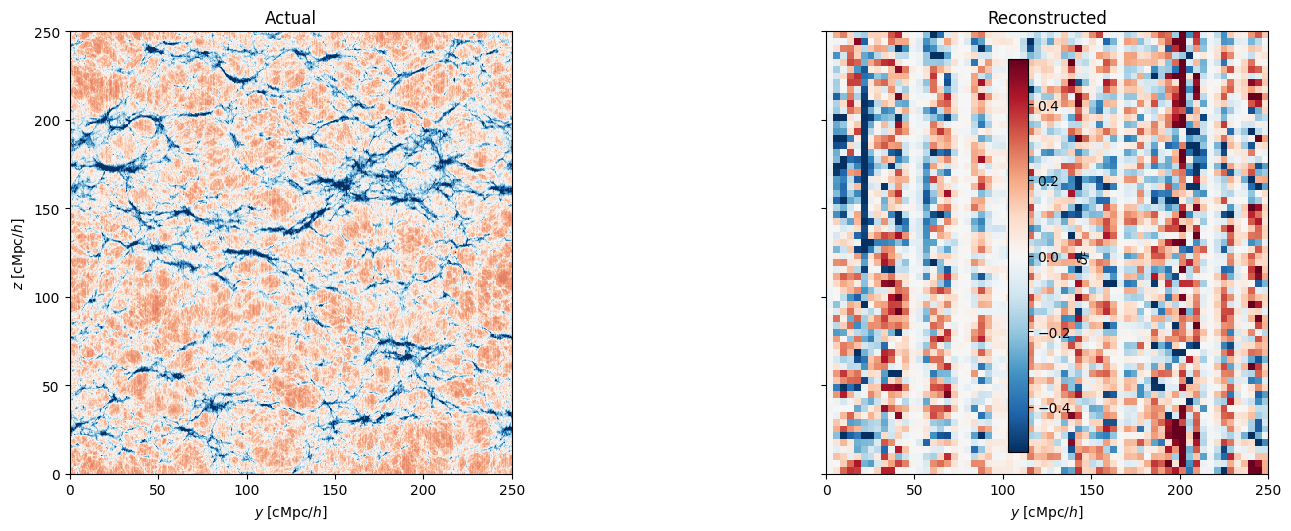

True slice: (1000, 1000) range: -0.924552248693643 0.27231749868994615
Recon slice: (64, 64) range: -0.9154917760459979 1.0538547632219226


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True)

vlim = np.percentile(np.abs(true_slice), 99)

for ax, field, title in zip(
    axes,
    [true_slice, recon_slice],
    ["Actual", "Reconstructed"],
):
    im = ax.imshow(
        field.T,
        origin="lower",
        extent=(0, L, 0, L),
        cmap="RdBu_r",
        vmin=-vlim,
        vmax=vlim,
        interpolation="nearest",
        aspect="equal",
    )
    ax.set_title(title)
    ax.set_xlabel(r"$y\;[\mathrm{cMpc}/h]$")

axes[0].set_ylabel(r"$z\;[\mathrm{cMpc}/h]$")
fig.colorbar(im, ax=axes, label=r"$\delta_F$", shrink=0.85)
plt.tight_layout(pad=1.5, w_pad=20.0, h_pad=1.0)
plt.savefig('side_view.png')
plt.show()

print("True slice:", true_slice.shape,
      "range:", true_slice.min(), true_slice.max())
print("Recon slice:", recon_slice.shape,
      "range:", recon_slice.min(), recon_slice.max())

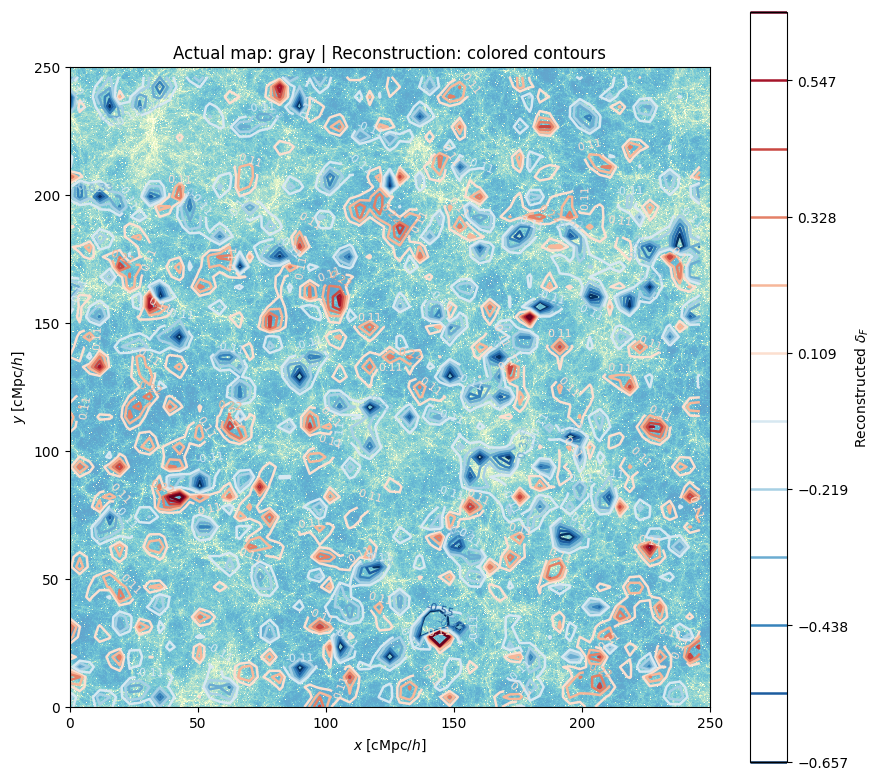

In [3]:
fig, ax = plt.subplots(figsize=(9, 8))

# Actual map
vlim = np.percentile(np.abs(true_slice), 99)
ax.pcolormesh(
    x_true, y_true, true_slice.T,
    shading="auto", cmap="YlGnBu",
    vmin=-vlim, vmax=vlim, alpha=0.7,
)

# Reconstructed map: blue = negative, red = positive
recon_limit = np.percentile(np.abs(recon_slice), 99)
levels = np.linspace(-recon_limit, recon_limit, 13)
levels = levels[~np.isclose(levels, 0)]

contours = ax.contour(
    x_recon, x_recon, recon_slice.T,
    levels=levels,
    cmap="RdBu_r",
    vmin=-recon_limit,
    vmax=recon_limit,
    linewidths=1.8,
)
ax.clabel(contours, inline=True, fontsize=8, fmt="%.2f")

fig.colorbar(contours, ax=ax, label=r"Reconstructed $\delta_F$")

ax.set(
    xlabel=r"$x\;[\mathrm{cMpc}/h]$",
    ylabel=r"$y\;[\mathrm{cMpc}/h]$",
    title="Actual map: gray | Reconstruction: colored contours",
    xlim=(0, L), ylim=(0, L),
)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()